# 06. Gassmann CO₂ fluid substitution (Lambert_8B, sand B)

**Thesis:** Machine-Learning Prediction of Shear-Wave Velocity in the Dampier Sub-basin: Accuracy, Errors and Applications (D. Aldosaimani, Curtin University, 2026)

**What this notebook does:** Checks the Angel Formation sand B in Lambert_8B (3,108–3,124 m), sets the mineral and fluid properties, and substitutes brine with CO₂ using Gassmann’s equation, once with the measured Vs and once with the blind Lasso Vs. Also runs the CO₂ saturation sweep, the Gassmann assumption checks and the reflection coefficient at the seal.

**Used in:** Sections 3.9 and 4.6; Appendix A, Tables A4–A6

**Needs:** `LAS_DIR` and `lasso_training_5wells.csv` from notebook 01 (set in the Settings cell below)

**Writes:** Changes in Vp, Vp/Vs and acoustic impedance for each run

## Settings

In [ ]:
from pathlib import Path

# ---- Settings: set these paths before running ----
LAS_DIR     = Path("../data/las")         # the eight *_LQC.las files from NOPIMS (project ENO0810814A)
RESULTS_DIR = Path("../results")          # results tables are written here
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## Step 1: load Lambert_8B and check the Angel Fm interval

Lambert_8B 3108-3124 m: 105 samples
  measured_vs  100.0%
  clean         96.2%
  brine        100.0%
  gauge        100.0%
  use           96.2%
  caliper reading exactly bit size: 100% (caliper not recorded below ~3,101 m)


,VCL_GEO_QEPP,PHIT_QEPP,SW_QEPP,RESD_EDITED,CALI_EDITED,RHOB_EDITED,VP_EDITED,VS_EDITED_V2
count,105.000,105.000,105.0,105.000,105.00,105.000,105.000,105.000
mean,0.102,0.199,1.0,1.095,12.25,2.336,3851.952,2250.780
std,0.080,0.025,0.0,0.404,0.00,0.049,96.569,85.563
min,0.060,0.113,1.0,0.840,12.25,2.290,3711.415,2133.897
10%,0.067,0.163,1.0,0.864,12.25,2.300,3747.262,2170.920
50%,0.080,0.209,1.0,0.920,12.25,2.316,3823.232,2223.607
90%,0.152,0.220,1.0,1.487,12.25,2.405,4004.975,2412.280
max,0.567,0.224,1.0,3.490,12.25,2.530,4100.039,2463.355


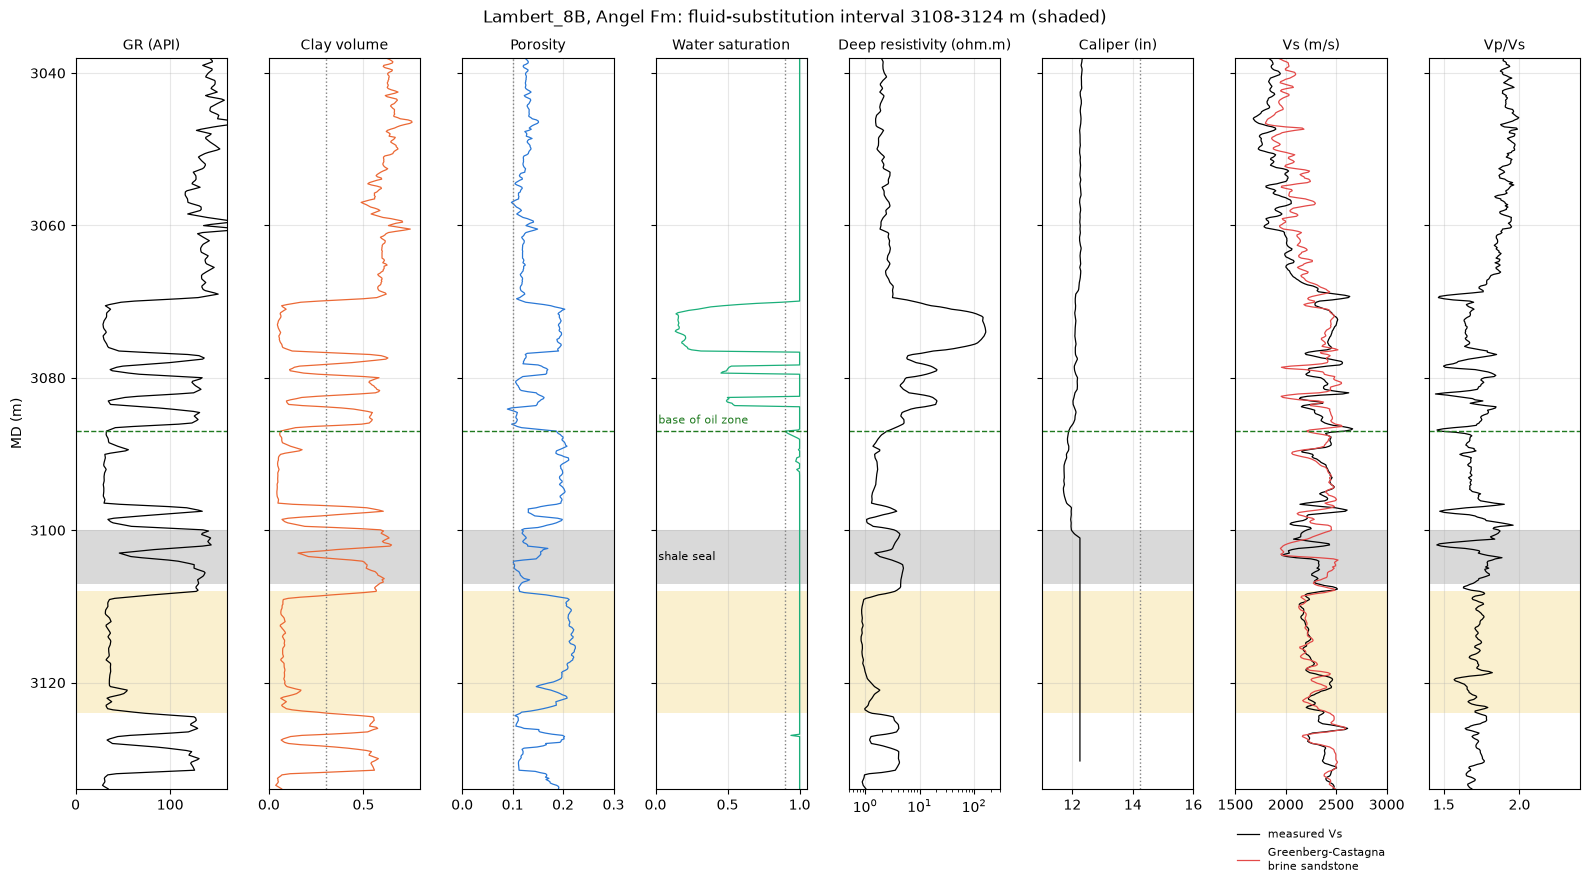

Samples used for fluid substitution: 101


In [2]:
# ---- Fluid substitution, Step 1: load Lambert_8B and check the Angel Fm interval ----
from pathlib import Path
import numpy as np
import pandas as pd
import lasio
import matplotlib.pyplot as plt

FIG_DIR = Path("figures_fluid_substitution_lambert")
FIG_DIR.mkdir(exist_ok=True)

WELL = "Lambert_8B"
TOP, BASE = 3108.0, 3124.0        # m MD, Angel Fm brine sand B
BIT = 12.25                       # in, bit size (12 1/4 in hole to 3,150 m)
OIL_BASE = 3087.0                 # m MD, base of the oil zone (oil above, from Sw and resistivity)
SHALE_TOP, SHALE_BASE = 3100.0, 3107.0   # m MD, shale between the oil zone and sand B

# Load the full-resolution LAS file (0.15 m spacing)
las = lasio.read(list(LAS_DIR.rglob(f"{WELL}_LQC.las"))[0]).df().reset_index()
las.columns = las.columns.str.upper()
las = las.rename(columns={las.columns[0]: "MD"}).replace([-999.25, -9999], np.nan)

# Interval QC flags
iv = las[(las["MD"] >= TOP) & (las["MD"] <= BASE)].copy()
iv["measured_vs"] = (iv["VS_EDITED_V2"] - iv["VS_ORG"]).abs() / iv["VS_ORG"] <= 0.02
iv["clean"]  = (iv["VCL_GEO_QEPP"] < 0.3) & (iv["CALCITE_COMBINER"] < 0.1) & (iv["PHIT_QEPP"] > 0.10)
iv["brine"]  = iv["SW_QEPP"] >= 0.9
iv["gauge"]  = iv["CALI_EDITED"] <= BIT + 2
iv["use"]    = iv["measured_vs"] & iv["clean"] & iv["brine"] & iv["gauge"]

# Greenberg-Castagna brine-sandstone line (km/s): Vs = 0.80416 Vp - 0.85588
iv["VS_GC"] = (0.80416 * iv["VP_EDITED"] / 1000 - 0.85588) * 1000

print(f"{WELL} {TOP:.0f}-{BASE:.0f} m: {len(iv)} samples")
for flag in ["measured_vs", "clean", "brine", "gauge", "use"]:
    print(f"  {flag:12s} {100 * iv[flag].mean():5.1f}%")
flat = (iv["CALI_ORG"].round(3) == BIT).mean()
print(f"  caliper reading exactly bit size: {100 * flat:.0f}% (caliper not recorded below ~3,101 m)")

display(iv[["VCL_GEO_QEPP", "PHIT_QEPP", "SW_QEPP", "RESD_EDITED", "CALI_EDITED",
            "RHOB_EDITED", "VP_EDITED", "VS_EDITED_V2"]].describe(percentiles=[0.1, 0.5, 0.9]).round(3))

# Depth plot: oil zone, shale seal and sand B
p = las[(las["MD"] >= TOP - 70) & (las["MD"] <= BASE + 10)].copy()
p["VS_GC"] = (0.80416 * p["VP_EDITED"] / 1000 - 0.85588) * 1000
p["VPVS"] = p["VP_EDITED"] / p["VS_EDITED_V2"]
tracks = [  # (title, [(column, colour, label)], x-limits, cut-off line)
    ("GR (API)",                 [("GR_EDITED", "k", "GR")],              (0, 160),    None),
    ("Clay volume",              [("VCL_GEO_QEPP", "#eb6834", "VCL")],    (0, 0.8),    0.3),
    ("Porosity",                 [("PHIT_QEPP", "#2a78d6", "PHIT")],      (0, 0.3),    0.10),
    ("Water saturation",         [("SW_QEPP", "#1baf7a", "Sw")],          (0, 1.05),   0.9),
    ("Deep resistivity (ohm.m)", [("RESD_EDITED", "k", "RESD")],          (0.5, 300),  None),
    ("Caliper (in)",             [("CALI_EDITED", "k", "CALI")],          (11, 16),    BIT + 2),
    ("Vs (m/s)",                 [("VS_EDITED_V2", "k", "measured Vs"),
                                  ("VS_GC", "#e34948", "Greenberg-Castagna\nbrine sandstone")], (1500, 3000), None),
    ("Vp/Vs",                    [("VPVS", "k", "Vp/Vs")],                (1.4, 2.4),  None),
]
fig, axs = plt.subplots(1, len(tracks), figsize=(16, 9), sharey=True)
for ax, (title, curves, xlim, cut) in zip(axs, tracks):
    ax.axhspan(TOP, BASE, color="#f8e6b0", alpha=0.6, lw=0)
    ax.axhspan(SHALE_TOP, SHALE_BASE, color="0.85", lw=0)
    for col, colour, label in curves:
        ax.plot(p[col], p["MD"], color=colour, lw=0.9, label=label)
    if cut is not None:
        ax.axvline(cut, color="grey", ls=":", lw=1)
    ax.axhline(OIL_BASE, color="#1f7a1f", ls="--", lw=1)
    if "resistivity" in title:
        ax.set_xscale("log")
    ax.set_xlim(*xlim)
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3)
axs[0].set_ylim(BASE + 10, TOP - 70)
axs[0].set_ylabel("MD (m)")
axs[6].legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), fontsize=8, frameon=False)
axs[3].text(0.02, OIL_BASE - 1, "base of oil zone", color="#1f7a1f", fontsize=8)
axs[3].text(0.02, (SHALE_TOP + SHALE_BASE) / 2, "shale seal", fontsize=8, va="center")
fig.suptitle(f"{WELL}, Angel Fm: fluid-substitution interval {TOP:.0f}-{BASE:.0f} m (shaded)")
plt.tight_layout()
plt.savefig(FIG_DIR / f"{WELL}_Angel_interval_check.png", dpi=300, bbox_inches="tight")
plt.show()

fs = iv[iv["use"]].copy()     # samples carried into the fluid substitution
print(f"Samples used for fluid substitution: {len(fs)}")

## Step 2: mineral bulk modulus K0 (quartz + clay, Voigt-Reuss-Hill)

In [3]:
# ---- Step 2: mineral bulk modulus K0 (quartz + clay, Voigt-Reuss-Hill) ----
K_QUARTZ = 37.0   # GPa, Mavko et al. (2009)
K_CLAY   = 21.0   # GPa, Han et al. (1986)

# Fractions of the solid (normalise quartz + clay to 1)
solid = fs["QUARTZ_COMBINER"] + fs["ILLITE_COMBINER"]
fq = fs["QUARTZ_COMBINER"] / solid
fc = fs["ILLITE_COMBINER"] / solid

voigt = fq * K_QUARTZ + fc * K_CLAY
reuss = 1 / (fq / K_QUARTZ + fc / K_CLAY)
fs["K0"] = (voigt + reuss) / 2          # GPa, used in Gassmann

print(f"Quartz {fq.median():.2f}, clay {fc.median():.2f}")
print(f"K0 median {fs['K0'].median():.2f} GPa (range {fs['K0'].min():.2f}-{fs['K0'].max():.2f})")

Quartz 0.91, clay 0.09
K0 median 35.11 GPa (range 31.98-35.55)


## Step 3: fluid properties (Batzle-Wang brine, CO2) and the 20% CO2 mix

In [4]:
# ---- Step 3: fluid properties (Batzle-Wang brine, CO2) and the 20% CO2 mix ----
from rockphypy import BW

P = 30.7      # MPa, RCI pretests in sand B (Lambert-8B WCR, Appendix 19)
T = 100.0     # °C, same pretests
S = 0.020     # salinity, weight fraction NaCl (~20,000 ppm)
G = 1.5349    # CO2 gas gravity

RHO_FL1, K_FL1 = BW.rho_K_brine(T, P, S)      # brine (g/cc, GPa)
RHO_CO2, K_CO2 = BW.rho_K_co2(P, T, G)        # CO2 (g/cc, GPa)

SCO2 = 0.20                                   # CO2 saturation
RHO_FL2 = (1 - SCO2) * RHO_FL1 + SCO2 * RHO_CO2          # density: linear mix
K_FL2 = 1 / ((1 - SCO2) / K_FL1 + SCO2 / K_CO2)          # bulk modulus: Wood/Reuss

print(f"Brine:      {RHO_FL1:.3f} g/cc, K = {K_FL1:.3f} GPa")
print(f"CO2:        {RHO_CO2:.3f} g/cc, K = {K_CO2:.3f} GPa")
print(f"20% CO2 mix: {RHO_FL2:.3f} g/cc, K = {K_FL2:.3f} GPa")

Brine:      0.987 g/cc, K = 2.607 GPa
CO2:        0.681 g/cc, K = 0.122 GPa
20% CO2 mix: 0.926 g/cc, K = 0.515 GPa


## Step 4: Gassmann substitution, brine -> 20% CO2 (measured Vs)

In [5]:
# ---- Step 4: Gassmann substitution, brine -> 20% CO2 (measured Vs) ----
from rockphypy import Fluid

def gassmann_co2(vp_ms, vs_ms, rho, phi, K0):
    vp, vs = vp_ms / 1000, vs_ms / 1000                  # km/s
    mu    = rho * vs**2                                  # shear modulus (GPa)
    ksat1 = rho * vp**2 - 4/3 * mu                       # bulk modulus with brine (GPa)
    ksat2 = Fluid.Gassmann_sub(phi, K0, ksat1, K_FL1, K_FL2)   # with CO2 mix
    rho2  = rho + phi * (RHO_FL2 - RHO_FL1)              # new density
    vp2   = np.sqrt((ksat2 + 4/3 * mu) / rho2) * 1000
    vs2   = np.sqrt(mu / rho2) * 1000
    a     = phi * K0 / K_FL1
    kdry  = (ksat1 * (a + 1 - phi) - K0) / (a + ksat1 / K0 - 1 - phi)   # dry-rock check
    return pd.DataFrame({"MU": mu, "KSAT1": ksat1, "KSAT2": ksat2, "KDRY": kdry,
                         "RHO2": rho2, "VP2": vp2, "VS2": vs2}, index=vp_ms.index)

m = gassmann_co2(fs["VP_EDITED"], fs["VS_EDITED_V2"], fs["RHOB_EDITED"], fs["PHIT_QEPP"], fs["K0"])

# Check: dry-rock modulus must lie between 0 and K0
ok = ((m["KDRY"] > 0) & (m["KDRY"] < fs["K0"])).mean()
print(f"K_dry between 0 and K0: {100 * ok:.0f}% of samples")
print(m[["MU", "KSAT1", "KDRY", "KSAT2"]].median().round(2).to_string(), "\n")

# Changes from brine to 20% CO2 (median %)
vpvs1 = fs["VP_EDITED"] / fs["VS_EDITED_V2"]
ai1   = fs["RHOB_EDITED"] * fs["VP_EDITED"] / 1000
changes = {
    "Vp":      100 * (m["VP2"] / fs["VP_EDITED"] - 1),
    "Vs":      100 * (m["VS2"] / fs["VS_EDITED_V2"] - 1),
    "Density": 100 * (m["RHO2"] / fs["RHOB_EDITED"] - 1),
    "Vp/Vs":   100 * ((m["VP2"] / m["VS2"]) / vpvs1 - 1),
    "AI":      100 * ((m["RHO2"] * m["VP2"] / 1000) / ai1 - 1),
}
print("Change from brine to 20% CO2 (median %, measured Vs):")
for k, v in changes.items():
    print(f"  {k:8s} {v.median():+.2f}%")

K_dry between 0 and K0: 100% of samples
MU       11.46
KSAT1    18.58
KDRY     14.92
KSAT2    15.69 

Change from brine to 20% CO2 (median %, measured Vs):
  Vp       -4.01%
  Vs       +0.28%
  Density  -0.55%
  Vp/Vs    -4.28%
  AI       -4.54%


## Step 5: Lasso-predicted Vs (Lambert_8B left out of training)

Whole-well RMSE: 102 m/s (main notebook: 102)
Sand B: mean error +148 m/s (+6.5%), RMSE 161 m/s
Median Vs: measured 2224, Lasso 2082 m/s


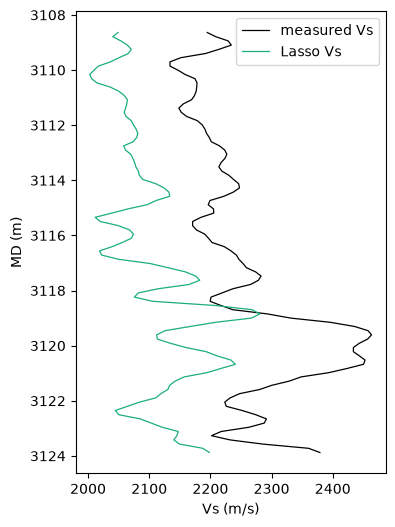

In [7]:
# ---- Step 5: Lasso-predicted Vs (Lambert_8B left out of training) ----
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

FEATURES = ["GR_EDITED", "RHOB_EDITED", "NPHI_EDITED", "RESD_LOG", "VP_EDITED"]
TARGET = "VS_EDITED_V2"

all5 = pd.read_csv(RESULTS_DIR / "lasso_training_5wells.csv")
train = all5[~all5["Well Name"].str.contains(WELL)]       # the other 4 wells
held  = all5[all5["Well Name"].str.contains(WELL)]

scaler = StandardScaler()
lasso = Lasso(alpha=7.279, max_iter=20000, tol=1e-3)
lasso.fit(scaler.fit_transform(train[FEATURES]), train[TARGET])

# Check against the main notebook (Lambert_8B LOWO RMSE = 102 m/s)
pred_held = lasso.predict(scaler.transform(held[FEATURES]))
print(f"Whole-well RMSE: {np.sqrt(((held[TARGET] - pred_held) ** 2).mean()):.0f} m/s (main notebook: 102)")

# Predict Vs in sand B
fs["RESD_LOG"] = np.log10(fs["RESD_EDITED"])
fs["VS_LASSO"] = lasso.predict(scaler.transform(fs[FEATURES]))
err = fs[TARGET] - fs["VS_LASSO"]                         # + = Lasso too low
print(f"Sand B: mean error {err.mean():+.0f} m/s ({100 * (err / fs[TARGET]).mean():+.1f}%), "
      f"RMSE {np.sqrt((err ** 2).mean()):.0f} m/s")
print(f"Median Vs: measured {fs[TARGET].median():.0f}, Lasso {fs['VS_LASSO'].median():.0f} m/s")

fig, ax = plt.subplots(figsize=(4, 6))
ax.plot(fs[TARGET], fs["MD"], "k", lw=0.9, label="measured Vs")
ax.plot(fs["VS_LASSO"], fs["MD"], color="#1baf7a", lw=0.9, label="Lasso Vs")
ax.invert_yaxis(); ax.set_xlabel("Vs (m/s)"); ax.set_ylabel("MD (m)"); ax.legend()
plt.show()

## Step 6: Gassmann with Lasso Vs, and compare with measured Vs

In [8]:
# ---- Step 6: Gassmann with Lasso Vs, and compare with measured Vs ----
l = gassmann_co2(fs["VP_EDITED"], fs["VS_LASSO"], fs["RHOB_EDITED"], fs["PHIT_QEPP"], fs["K0"])

ok = ((l["KDRY"] > 0) & (l["KDRY"] < fs["K0"])).mean()
print(f"Lasso run: K_dry between 0 and K0 in {100 * ok:.0f}% of samples\n")

moduli = pd.DataFrame({"Measured Vs": m[["MU", "KSAT1", "KDRY", "KSAT2"]].median(),
                       "Lasso Vs":    l[["MU", "KSAT1", "KDRY", "KSAT2"]].median()}).round(2)
display(moduli)

def pct_changes(res, vs):
    vpvs1 = fs["VP_EDITED"] / vs
    ai1   = fs["RHOB_EDITED"] * fs["VP_EDITED"] / 1000
    return {"Vp":      (100 * (res["VP2"] / fs["VP_EDITED"] - 1)).median(),
            "Vs":      (100 * (res["VS2"] / vs - 1)).median(),
            "Density": (100 * (res["RHO2"] / fs["RHOB_EDITED"] - 1)).median(),
            "Vp/Vs":   (100 * ((res["VP2"] / res["VS2"]) / vpvs1 - 1)).median(),
            "AI":      (100 * ((res["RHO2"] * res["VP2"] / 1000) / ai1 - 1)).median()}

table = pd.DataFrame({"Measured Vs (%)": pct_changes(m, fs["VS_EDITED_V2"]),
                      "Lasso Vs (%)":    pct_changes(l, fs["VS_LASSO"])})
table["Lasso / measured"] = table["Lasso Vs (%)"] / table["Measured Vs (%)"]
print("Change from brine to 20% CO2 (median):")
display(table.round(2))

Lasso run: K_dry between 0 and K0 in 100% of samples



,Measured Vs,Lasso Vs
MU,11.46,10.00
KSAT1,18.58,20.35
KDRY,14.92,17.51
KSAT2,15.69,18.10


Change from brine to 20% CO2 (median):


,Measured Vs (%),Lasso Vs (%),Lasso / measured
Vp,-4.01,-3.04,0.76
Vs,0.28,0.28,1.00
Density,-0.55,-0.55,1.00
Vp/Vs,-4.28,-3.31,0.77
AI,-4.54,-3.58,0.79


## Plots: measured Vs run vs Lasso Vs run

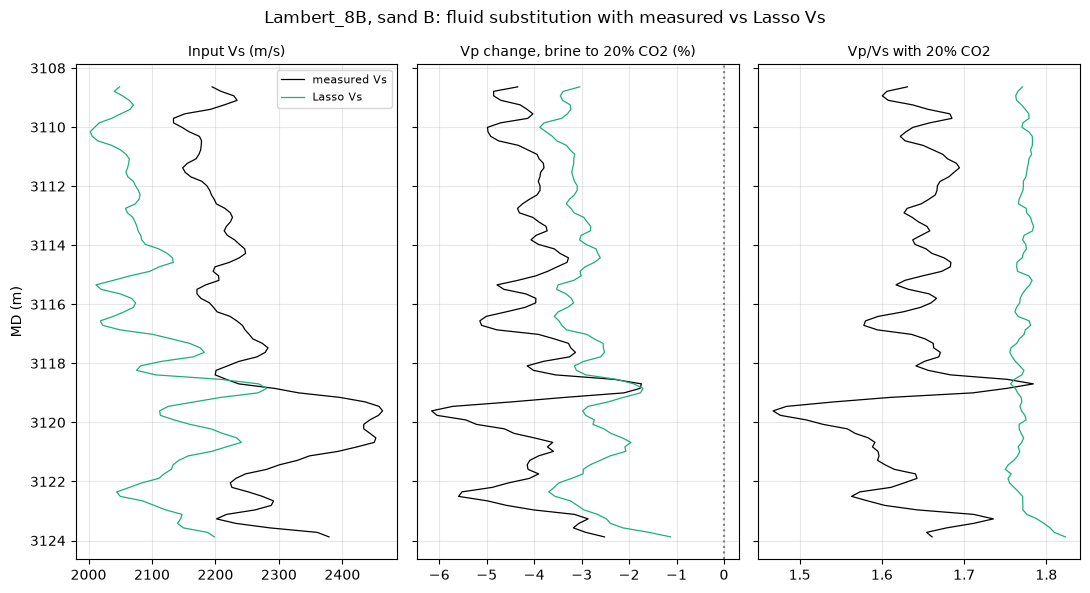

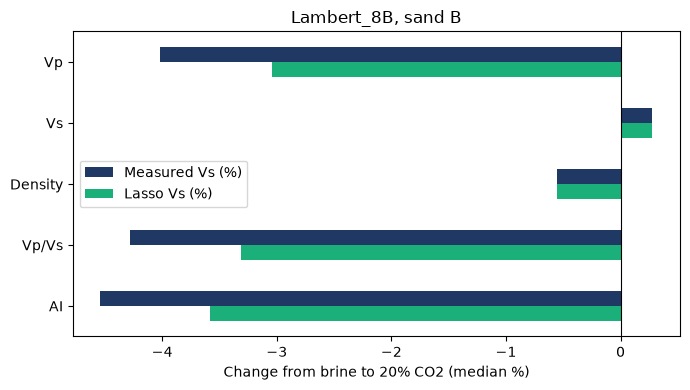

In [9]:
# ---- Plots: measured Vs run vs Lasso Vs run ----
d = fs.copy()
d["DVP_MEAS"]  = 100 * (m["VP2"] / d["VP_EDITED"] - 1)
d["DVP_LASSO"] = 100 * (l["VP2"] / d["VP_EDITED"] - 1)
d["VPVS2_MEAS"]  = m["VP2"] / m["VS2"]
d["VPVS2_LASSO"] = l["VP2"] / l["VS2"]
d = d.sort_values("MD")

# 1) Depth plot
fig, axs = plt.subplots(1, 3, figsize=(11, 6), sharey=True)
pairs = [("VS_EDITED_V2", "VS_LASSO", "Input Vs (m/s)"),
         ("DVP_MEAS", "DVP_LASSO", "Vp change, brine to 20% CO2 (%)"),
         ("VPVS2_MEAS", "VPVS2_LASSO", "Vp/Vs with 20% CO2")]
for ax, (a, b, title) in zip(axs, pairs):
    ax.plot(d[a], d["MD"], "k", lw=0.9, label="measured Vs")
    ax.plot(d[b], d["MD"], color="#1baf7a", lw=0.9, label="Lasso Vs")
    ax.set_title(title, fontsize=10); ax.grid(alpha=0.3)
axs[1].axvline(0, color="grey", ls=":")
axs[0].invert_yaxis(); axs[0].set_ylabel("MD (m)"); axs[0].legend(fontsize=8)
fig.suptitle(f"{WELL}, sand B: fluid substitution with measured vs Lasso Vs")
plt.tight_layout(); plt.show()

# 2) Bar chart of the median changes
ax = table[["Measured Vs (%)", "Lasso Vs (%)"]].plot.barh(color=["#1f3864", "#1baf7a"], figsize=(7, 4))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Change from brine to 20% CO2 (median %)")
ax.set_title(f"{WELL}, sand B")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

## Step 7: CO2 saturation sweep, measured vs Lasso Vs

prop        AI                   Vp                Vp/Vs            
run   Lasso Vs measured Vs Lasso Vs measured Vs Lasso Vs measured Vs
S_CO2                                                               
0.05     -2.07       -2.63    -1.94       -2.50    -2.01       -2.57
0.10     -2.85       -3.63    -2.58       -3.37    -2.72       -3.50
0.20     -3.58       -4.54    -3.04       -4.01    -3.31       -4.28
0.30     -3.98       -5.02    -3.16       -4.24    -3.57       -4.62
0.40     -4.26       -5.34    -3.17       -4.30    -3.71       -4.81
0.60     -4.70       -5.83    -3.04       -4.25    -3.87       -5.02
0.80     -5.06       -6.22    -2.87       -4.10    -3.95       -5.13
1.00     -5.37       -6.57    -2.68       -3.90    -4.01       -5.20

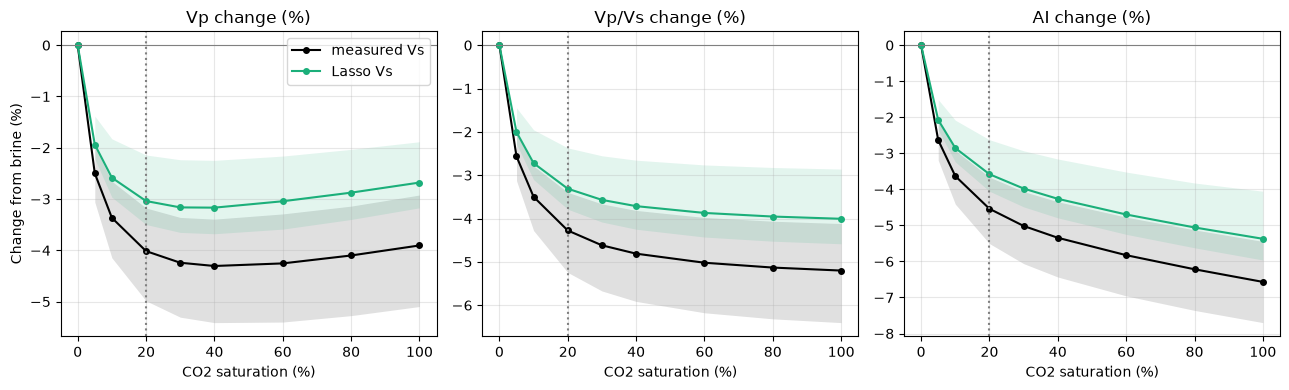

In [10]:
# ---- Step 7: CO2 saturation sweep, measured vs Lasso Vs ----
SATS = [0.05, 0.10, 0.20, 0.30, 0.40, 0.60, 0.80, 1.00]

def sub(vs, s):
    rho_fl2 = (1 - s) * RHO_FL1 + s * RHO_CO2
    k_fl2 = 1 / ((1 - s) / K_FL1 + s / K_CO2)
    vp, vsk = fs["VP_EDITED"] / 1000, vs / 1000
    rho, phi = fs["RHOB_EDITED"], fs["PHIT_QEPP"]
    mu = rho * vsk**2
    k1 = rho * vp**2 - 4/3 * mu
    k2 = Fluid.Gassmann_sub(phi, fs["K0"], k1, K_FL1, k_fl2)
    rho2 = rho + phi * (rho_fl2 - RHO_FL1)
    vp2, vs2 = np.sqrt((k2 + 4/3 * mu) / rho2), np.sqrt(mu / rho2)
    return {"Vp": 100 * (vp2 / vp - 1),
            "Vp/Vs": 100 * ((vp2 / vs2) / (vp / vsk) - 1),
            "AI": 100 * (rho2 * vp2 / (rho * vp) - 1)}

rows = []
for run, vs in [("measured Vs", fs["VS_EDITED_V2"]), ("Lasso Vs", fs["VS_LASSO"])]:
    for s in SATS:
        for prop, v in sub(vs, s).items():
            rows.append({"run": run, "S_CO2": s, "prop": prop,
                         "median": v.median(), "P10": v.quantile(0.1), "P90": v.quantile(0.9)})
sweep = pd.DataFrame(rows)
display(sweep.pivot_table(index="S_CO2", columns=["prop", "run"], values="median").round(2))

fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, prop in zip(axs, ["Vp", "Vp/Vs", "AI"]):
    for run, c in [("measured Vs", "k"), ("Lasso Vs", "#1baf7a")]:
        d = sweep[(sweep["prop"] == prop) & (sweep["run"] == run)]
        ax.plot([0] + list(100 * d["S_CO2"]), [0] + list(d["median"]), color=c, marker="o", ms=4, label=run)
        ax.fill_between(100 * d["S_CO2"], d["P10"], d["P90"], color=c, alpha=0.12, lw=0)
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(20, color="grey", ls=":")
    ax.set_title(f"{prop} change (%)")
    ax.set_xlabel("CO2 saturation (%)")
    ax.grid(alpha=0.3)
axs[0].set_ylabel("Change from brine (%)")
axs[0].legend()
plt.tight_layout(); plt.show()

## Step 8: Gassmann assumption checks

In [11]:
# ---- Step 8: Gassmann assumption checks ----
# (a) Connected pores: log permeability
k = fs["KINT_GEO_QEPP"]
print(f"(a) Permeability: median {k.median():.0f} mD, samples below 1 mD: {(k < 1).sum()}")

# (b) Low frequency: Biot characteristic frequency f_c = phi*eta / (2*pi*rho_fl*k)
eta_cp = 0.1 + 0.333*S + (1.65 + 91.9*S**3) * np.exp(-(0.42*(S**0.8 - 0.17)**2 + 0.045) * T**0.8)  # Batzle-Wang, cP
f_c = fs["PHIT_QEPP"] * eta_cp * 1e-3 / (2 * np.pi * RHO_FL1 * 1000 * k * 9.869e-16)              # Hz
print(f"(b) Brine viscosity {eta_cp:.3f} cP; f_c median {f_c.median()/1e3:,.0f} kHz, lowest {f_c.min()/1e3:,.0f} kHz")
print(f"    sonic (20 kHz) / f_c: median {20e3 / f_c.median():.3f}, worst {20e3 / f_c.min():.3f}")

# (c) Clay modulus sensitivity: rerun 20% CO2 with clay K = 21, 35, 50 GPa
rows = []
for k_clay in [21.0, 35.0, 50.0]:
    K0_test = 0.5 * ((fq * K_QUARTZ + fc * k_clay) + 1 / (fq / K_QUARTZ + fc / k_clay))
    gm = gassmann_co2(fs["VP_EDITED"], fs["VS_EDITED_V2"], fs["RHOB_EDITED"], fs["PHIT_QEPP"], K0_test)
    gl = gassmann_co2(fs["VP_EDITED"], fs["VS_LASSO"],     fs["RHOB_EDITED"], fs["PHIT_QEPP"], K0_test)
    dm = (100 * (gm["VP2"] / fs["VP_EDITED"] - 1)).median()
    dl = (100 * (gl["VP2"] / fs["VP_EDITED"] - 1)).median()
    rows.append({"clay K (GPa)": k_clay, "K0 (GPa)": K0_test.median(),
                 "dVp % measured": dm, "dVp % Lasso": dl, "Lasso / measured": dl / dm})
print("(c) Clay modulus sensitivity (20% CO2):")
display(pd.DataFrame(rows).set_index("clay K (GPa)").round(2))

(a) Permeability: median 90 mD, samples below 1 mD: 1
(b) Brine viscosity 0.317 cP; f_c median 121 kHz, lowest 76 kHz
    sonic (20 kHz) / f_c: median 0.166, worst 0.264
(c) Clay modulus sensitivity (20% CO2):


,K0 (GPa),dVp % measured,dVp % Lasso,Lasso / measured
clay K (GPa),,,,
21.0,35.11,-4.01,-3.04,0.76
35.0,36.82,-4.49,-3.53,0.78
50.0,38.02,-4.85,-3.82,0.79


In [ ]:
# ---- Step 8 (c, continued): clay modulus sensitivity for acoustic impedance (Table A5) ----
rows = []
ai0 = fs["RHOB_EDITED"] * fs["VP_EDITED"]
for k_clay in [21.0, 35.0, 50.0]:
    K0_test = 0.5 * ((fq * K_QUARTZ + fc * k_clay) + 1 / (fq / K_QUARTZ + fc / k_clay))
    gm = gassmann_co2(fs["VP_EDITED"], fs["VS_EDITED_V2"], fs["RHOB_EDITED"], fs["PHIT_QEPP"], K0_test)
    gl = gassmann_co2(fs["VP_EDITED"], fs["VS_LASSO"],     fs["RHOB_EDITED"], fs["PHIT_QEPP"], K0_test)
    am = (100 * (gm["RHO2"] * gm["VP2"] / ai0 - 1)).median()
    al = (100 * (gl["RHO2"] * gl["VP2"] / ai0 - 1)).median()
    rows.append({"clay K (GPa)": k_clay, "dAI % measured": am, "dAI % Lasso": al,
                 "Lasso / measured (AI)": al / am})
print("Clay modulus sensitivity, acoustic impedance (20% CO2):")
display(pd.DataFrame(rows).set_index("clay K (GPa)").round(2))


## Step 9: normal-incidence reflection coefficient, shale over sand B

Shale 3100-3107 m: GR 130 API, VCL 0.57, AI 9.830
Sand B AI with brine: 8.822, R with brine: -0.0540


,R measured,dR % measured,R Lasso,dR % Lasso
S_CO2 (%),,,,
0.0,-0.0540,-0.0000,-0.0540,-0.0000
5.0,-0.0673,24.5939,-0.0645,19.3064
10.0,-0.0725,34.0865,-0.0685,26.6846
20.0,-0.0772,42.7995,-0.0722,33.5982
30.0,-0.0796,47.3992,-0.0742,37.3971
40.0,-0.0814,50.5762,-0.0757,40.1323
60.0,-0.0839,55.2749,-0.0780,44.3219
80.0,-0.0860,59.0991,-0.0799,47.7974
100.0,-0.0878,62.5367,-0.0815,50.8516


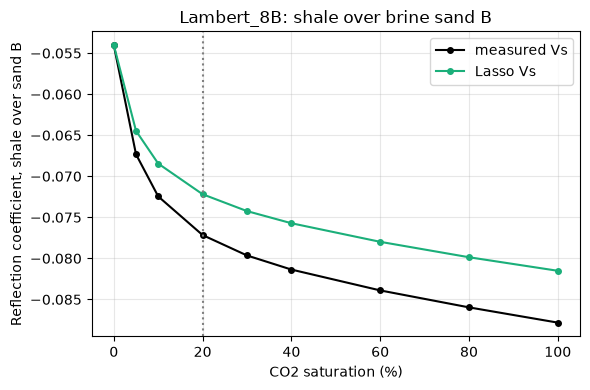

In [12]:
# ---- Step 9: normal-incidence reflection coefficient, shale over sand B ----
SEAL_TOP, SEAL_BASE = 3100.0, 3107.0       # shale directly above sand B
seal = las[(las["MD"] >= SEAL_TOP) & (las["MD"] <= SEAL_BASE)]
AI_SEAL = (seal["RHOB_EDITED"] * seal["VP_EDITED"] / 1000).median()
print(f"Shale {SEAL_TOP:.0f}-{SEAL_BASE:.0f} m: GR {seal['GR_EDITED'].median():.0f} API, "
      f"VCL {seal['VCL_GEO_QEPP'].median():.2f}, AI {AI_SEAL:.3f}")

ai_brine = (fs["RHOB_EDITED"] * fs["VP_EDITED"] / 1000).median()
r0 = (ai_brine - AI_SEAL) / (ai_brine + AI_SEAL)
print(f"Sand B AI with brine: {ai_brine:.3f}, R with brine: {r0:.4f}")

rows = []
for s in [0.0] + SATS:
    row = {"S_CO2 (%)": 100 * s}
    for run, vs in [("measured", fs["VS_EDITED_V2"]), ("Lasso", fs["VS_LASSO"])]:
        dai = sub(vs, s)["AI"].median() if s > 0 else 0.0
        ai = ai_brine * (1 + dai / 100)
        r = (ai - AI_SEAL) / (ai + AI_SEAL)
        row[f"R {run}"] = r
        row[f"dR % {run}"] = 100 * (r - r0) / r0
    rows.append(row)
refl = pd.DataFrame(rows).set_index("S_CO2 (%)")
display(refl.round(4))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(refl.index, refl["R measured"], "k-o", ms=4, label="measured Vs")
ax.plot(refl.index, refl["R Lasso"], "-o", color="#1baf7a", ms=4, label="Lasso Vs")
ax.axvline(20, color="grey", ls=":")
ax.set_xlabel("CO2 saturation (%)"); ax.set_ylabel("Reflection coefficient, shale over sand B")
ax.set_title(f"{WELL}: shale over brine sand B"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## Plot: how the Vs error carries into the CO2 response

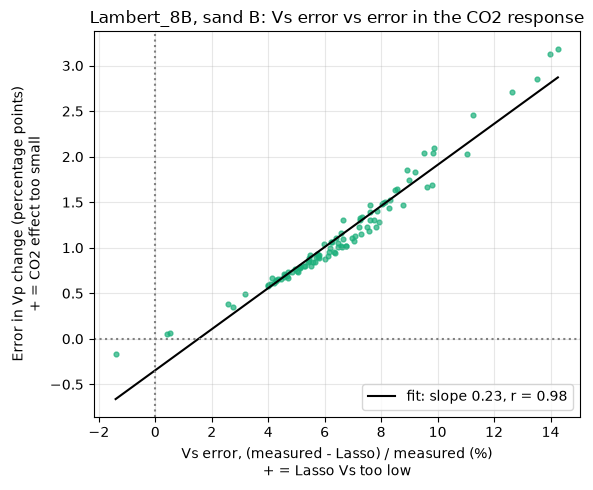

In [13]:
# ---- Plot: how the Vs error carries into the CO2 response ----
vs_err = 100 * (fs["VS_EDITED_V2"] - fs["VS_LASSO"]) / fs["VS_EDITED_V2"]   # % (+ = Lasso too low)
dvp_m = 100 * (m["VP2"] / fs["VP_EDITED"] - 1)
dvp_l = 100 * (l["VP2"] / fs["VP_EDITED"] - 1)
resp_err = dvp_l - dvp_m                     # percentage points (+ = CO2 effect too small)

slope, intercept = np.polyfit(vs_err, resp_err, 1)
r = np.corrcoef(vs_err, resp_err)[0, 1]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(vs_err, resp_err, s=12, color="#1baf7a", alpha=0.7)
x = np.linspace(vs_err.min(), vs_err.max(), 50)
ax.plot(x, slope * x + intercept, "k", label=f"fit: slope {slope:.2f}, r = {r:.2f}")
ax.axhline(0, color="grey", ls=":"); ax.axvline(0, color="grey", ls=":")
ax.set_xlabel("Vs error, (measured - Lasso) / measured (%)\n+ = Lasso Vs too low")
ax.set_ylabel("Error in Vp change (percentage points)\n+ = CO2 effect too small")
ax.set_title(f"{WELL}, sand B: Vs error vs error in the CO2 response")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Plot: CO2 response, Lasso run vs measured run

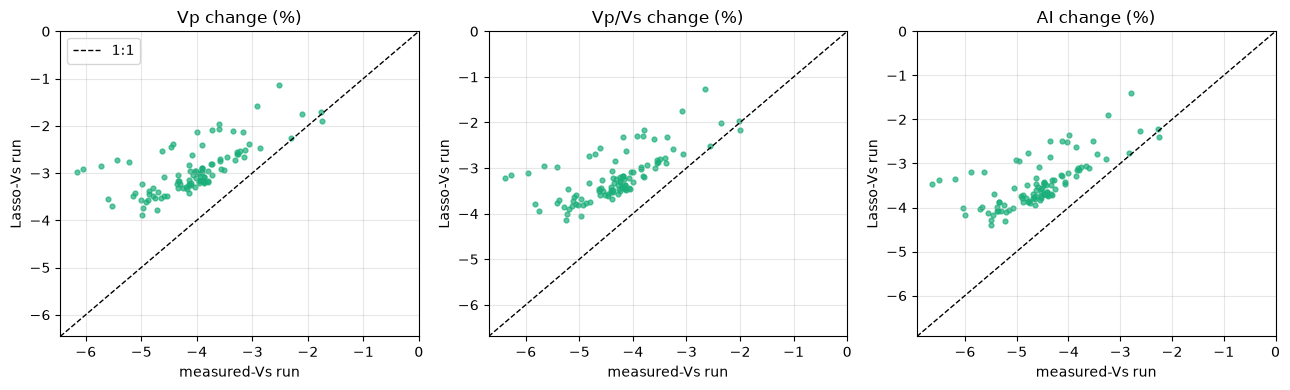

In [14]:
# ---- Plot: CO2 response, Lasso run vs measured run ----
pairs = {"Vp change (%)": (dvp_m, dvp_l),
         "Vp/Vs change (%)": (100 * ((m["VP2"] / m["VS2"]) / (fs["VP_EDITED"] / fs["VS_EDITED_V2"]) - 1),
                              100 * ((l["VP2"] / l["VS2"]) / (fs["VP_EDITED"] / fs["VS_LASSO"]) - 1)),
         "AI change (%)": (100 * (m["RHO2"] * m["VP2"] / (fs["RHOB_EDITED"] * fs["VP_EDITED"]) - 1),
                           100 * (l["RHO2"] * l["VP2"] / (fs["RHOB_EDITED"] * fs["VP_EDITED"]) - 1))}
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, (title, (a, b)) in zip(axs, pairs.items()):
    ax.scatter(a, b, s=12, color="#1baf7a", alpha=0.7)
    lim = [min(a.min(), b.min()) - 0.3, 0]
    ax.plot(lim, lim, "k--", lw=1, label="1:1")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("measured-Vs run"); ax.set_ylabel("Lasso-Vs run")
    ax.set_title(title); ax.grid(alpha=0.3)
axs[0].legend()
plt.tight_layout(); plt.show()